# SWOT L2 LR SSH Expert (version D) as a `(cycle, pass)` virtual cube
### VirtualiZarr 2.x + Icechunk (NASA CMR short name: `SWOT_L2_LR_SSH_EXPERT_D`)

This notebook is a companion to `vz2_icechunk_SWOT_L2_SSH_EXPERT_D.ipynb`. Both build one Icechunk store of
virtual references to the SWOT L2 LR SSH Expert granules. They differ in how the granules are combined:

| | `granule` concat (existing notebook) | `(cycle, pass)` cube (this notebook) |
|---|---|---|
| Swath variables | `(granule, num_lines, num_pixels)` | `(cycle, pass_number, num_lines, num_pixels)` |
| Repeat-track statistics (same ground track across cycles) | `groupby("ppass")` or index arithmetic | `ds.sel(pass_number=p).mean("cycle")` |
| Regional subset | scan lat/lon of every granule | lat/lon are one fixed grid per pass, so pick passes + line ranges once |
| Missing granules | absent rows | explicit holes: null chunk references, plus a `granule_present` flag |
| Swath `latitude` / `longitude` | repeated for every granule | stored once per pass, as `(pass_number, num_lines, num_pixels)` |
| Nadir `latitude_nadir` / `longitude_nadir` | taken from the **first granule only** (`compat="override"`) | per granule, as `(cycle, pass_number, num_lines)` |
| New granules | append along `granule` | append an empty `cycle` if needed, then region-write the slots |
| S3 vs HTTPS access | one store per access method, each holding absolute URLs | **one store**: relative `vcc://podaac-swot/...` references, resolved to S3 or HTTPS when the store is opened |

**Why the cube works for SWOT:** in the 21-day science orbit, pass *N* follows the same ground track every cycle.
The L2 LR swath is also delivered on a **fixed grid** for each pass: line *i*, pixel *j* is the same location in
every cycle (Section 2 checks this). So reductions over `cycle` (mean SSH, variability, anomalies) are meaningful
directly on the arrays.

The nadir track, by contrast, does move between cycles, by hundreds of metres up to about 1.6 km. That's why nadir
coordinates must be stored per granule.

**Scope:** science phase only (cycle 1 starts 2023-07-26). The Cal/Val phase (1-day repeat, 28 passes) does not fit
the 584-pass axis and would belong in a separate store or group. This demo builds a small subset (configurable
below) over **HTTPS**, so it runs anywhere with Earthdata Login credentials. See the closing notes for running it
in-region with S3.

**Contents**
1. Find granules
2. Check that the swath grid is fixed across cycles
3. Parse granules into virtual datasets
4. Assemble cube blocks (null references for holes)
5. Write to Icechunk: empty template, then region writes
6. Open the cube
7. Verify against the source files
8. Analysis examples
9. Incremental updates (append cycle + region write)
10. Notes and limitations

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")            # tqdm, via earthaccess
warnings.filterwarnings("ignore", message="invalid value encountered", category=RuntimeWarning)  # all-NaN cells
warnings.filterwarnings("ignore", message="Numcodecs codecs*", category=UserWarning)

import re
import shutil
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path

import earthaccess  # CMR granule search only; no login needed for search
import earthaccess_auth
import icechunk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import virtualizarr as vz
import xarray as xr
import zarr
from earthaccess_auth.adapters.icechunk import earthdata_containers_credentials
from earthaccess_auth.adapters.obstore import http_client_options
from obspec_utils.readers import BlockStoreReader, EagerStoreReader
from obspec_utils.registry import ObjectStoreRegistry
from obstore.store import HTTPStore
from virtualizarr import open_virtual_dataset
from virtualizarr.manifests import ChunkManifest, ManifestArray
from virtualizarr.manifests.utils import copy_and_replace_metadata
from virtualizarr.parsers import HDFParser

for m in (earthaccess, earthaccess_auth, vz, zarr, xr, icechunk, np):
    print(f"{m.__name__}: {m.__version__}")

earthaccess: 0.19.0
earthaccess_auth: 0.4.0
virtualizarr: 2.8.0
zarr: 3.4.2
xarray: 2026.9.0
icechunk: 2.3.1
numpy: 2.5.5


### Configuration
The cube always has all 584 passes on the `pass_number` axis, because the orbit fixes them. `PASSES` only limits
which slots this demo fills. `DROP` leaves a slot empty on purpose, to show holes; Section 9 fills it later.

In [2]:
SHORT_NAME = "SWOT_L2_LR_SSH_EXPERT_D"
N_PASSES = 584                      # passes per 21-day science cycle
CYCLES = list(range(10, 20))        # cycles to build
PASSES = list(range(1, 9))          # passes to populate in each cycle
DROP = {(11, 5)}                    # (cycle, pass) slots to leave empty for the demo

REPO_PATH = "SWOT_L2_LR_SSH_EXPERT_D_cycle_pass.icechunk"

HTTPS_HOST = "https://archive.swot.podaac.earthdata.nasa.gov/"
S3_BUCKET = "podaac-swot-ops-cumulus-protected"
HTTPS_PREFIX = HTTPS_HOST + S3_BUCKET + "/"
S3_PREFIX = f"s3://{S3_BUCKET}/"
VCC_NAME = "podaac-swot"            # virtual chunk container name; references are relative to it
VCC_ROOT = f"vcc://{VCC_NAME}/"
DROP_VARS = ["polarization_karin"]  # fixed-length character array; cannot be virtualized
GRID_VARS = ["latitude", "longitude"]  # fixed per pass: stored without a cycle dim
LEAD = ("cycle", "pass_number")

### Earthdata Login with `earthaccess-auth`
Authentication uses [`earthaccess-auth`](https://github.com/earthaccess-dev/earthaccess-auth), the Earthdata Login
core extracted from earthaccess, with integrations for obstore and icechunk. It's a minimal dependency for code that
only needs auth, such as a service that opens this cube. The full `earthaccess` package is used here only for the
CMR granule search, which needs no login.

`http_client_options(auth)` returns `{"default_headers": {"authorization": "Bearer ..."}}`. That's the shape
obstore's `HTTPStore` expects, and its `default_headers` are what icechunk's `http_store(headers=...)` takes for the
virtual chunk container.

In [3]:
auth = earthaccess_auth.login(strategy="netrc")  # also: "environment", "interactive", "all"
token = auth.token["access_token"]  # used below only to check it never lands in the repo

## 1. Find granules
One granule per `(cycle, pass)`. If a slot has more than one file, prefer reprocessed `PGD` over forward-stream
`PID`, then the highest product counter. Without this rule, duplicate granules would silently collide.

In [4]:
NAME_RE = re.compile(
    r"SWOT_L2_LR_SSH_Expert_(\d{3})_(\d{3})_\d{8}T\d{6}_\d{8}T\d{6}_(\w{4})_(\d{2})\.nc$"
)


@dataclass(frozen=True)
class Granule:
    cycle: int
    pass_number: int
    crid: str
    counter: int
    url: str

    @property
    def filename(self):
        return self.url.rsplit("/", 1)[-1]

    @property
    def rank(self):
        return (self.crid.startswith("PGD"), self.counter)


def rank_filename(fname):
    m = NAME_RE.search(fname)
    return (m[3].startswith("PGD"), int(m[4])) if m else None


def find_granules(cycles, passes):
    found, pass_set = {}, set(passes)
    for c in cycles:
        for g in earthaccess.search_data(
            short_name=SHORT_NAME, granule_name=f"SWOT_L2_LR_SSH_Expert_{c:03d}_*.nc"
        ):
            url = g.data_links(access="external")[0]
            m = NAME_RE.search(url)
            if not m or int(m[2]) not in pass_set:
                continue
            gr = Granule(int(m[1]), int(m[2]), m[3], int(m[4]), url)
            key = (gr.cycle, gr.pass_number)
            if key not in found or gr.rank > found[key].rank:
                found[key] = gr
    return sorted(found.values(), key=lambda g: (g.cycle, g.pass_number))


granules = [g for g in find_granules(CYCLES, PASSES) if (g.cycle, g.pass_number) not in DROP]
print(f"{len(granules)} granules for {len(CYCLES)} cycles x {len(PASSES)} passes "
      f"({len(CYCLES) * len(PASSES) - len(granules)} empty slots, {len(DROP)} dropped on purpose)")
pd.Series([g.crid for g in granules]).value_counts()

79 granules for 10 cycles x 8 passes (1 empty slots, 1 dropped on purpose)


PGD0    79
Name: count, dtype: int64

## 2. Is the swath grid fixed across cycles?
The design depends on this, so check it directly. Read `latitude`/`longitude` (swath and nadir) for one pass in
several cycles and measure how far each point moves compared with the first. The pixel spacing is 2 km.

`read_direct` reads a source file without VirtualiZarr. It uses an obstore `HTTPStore` authorized by `earthaccess-auth`, and
`EagerStoreReader` fetches the whole file (about 35 MB) in parallel range requests.

In [5]:
def make_store():
    return HTTPStore.from_url(HTTPS_HOST, client_options=http_client_options(auth))


def read_direct(url, variables=None):
    reader = EagerStoreReader(make_store(), url.removeprefix(HTTPS_HOST))
    with xr.open_dataset(reader, engine="h5netcdf", drop_variables=DROP_VARS) as ds:
        return (ds[variables] if variables else ds).load()


def haversine_m(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6_371_000 * np.arcsin(np.sqrt(a))


probe_pass = PASSES[2]
probe = [g for g in granules if g.pass_number == probe_pass][:4]
coord_vars = ["latitude", "longitude", "latitude_nadir", "longitude_nadir"]
with ThreadPoolExecutor(4) as ex:
    coords = list(ex.map(lambda g: read_direct(g.url, coord_vars), probe))

ref = coords[0]
rows = []
for g, c in zip(probe, coords):
    d = haversine_m(ref.latitude, ref.longitude, c.latitude, c.longitude)
    dn = haversine_m(ref.latitude_nadir, ref.longitude_nadir, c.latitude_nadir, c.longitude_nadir)
    rows.append({"cycle": g.cycle, "swath_max_m": float(d.max()),
                 "nadir_median_m": float(dn.median()), "nadir_max_m": float(dn.max())})
pd.DataFrame(rows).round(1)

,cycle,swath_max_m,nadir_median_m,nadir_max_m
0,10,0.0,0.0,0.0
1,11,0.0,228.2,321.5
2,12,0.0,271.1,396.0
3,13,0.0,180.7,1682.4


The swath moves about 0.1 m at most, which is the storage precision (int32 with a 1e-6° scale factor), so the
grid is identical across cycles. The nadir track moves hundreds of metres. Outside this notebook, the same result
held for passes 13 and 300 sampled across cycles 1–49.

## 3. Parse granules into virtual datasets
**Reader choice:** VirtualiZarr's default `BlockStoreReader` makes many small requests for HDF5 metadata. Over
HTTPS from outside AWS, each request pays the Earthdata redirect, which comes to about 80 s per granule.
`EagerStoreReader` downloads the whole file in parallel ranges instead: about 12 s per granule. In-region over S3,
latency is low and the block reader avoids downloading whole files, so it is probably the better choice there.

Threads only help with the eager reader. h5py's global lock serializes HDF5 parsing, but the eager download runs
outside that lock.

In [6]:
def make_registry():
    return ObjectStoreRegistry({HTTPS_HOST: make_store()})


def parse_granules(granules, workers=8, eager=True):
    registry = make_registry()
    parser = HDFParser(drop_variables=DROP_VARS,
                       reader_factory=EagerStoreReader if eager else BlockStoreReader)

    def _open(g):
        return open_virtual_dataset(g.url, registry=registry, parser=parser, loadable_variables=[])

    with ThreadPoolExecutor(workers) as ex:
        return [to_relative(v) for v in ex.map(_open, granules)]


def to_relative(vds):
    # Rewrite absolute S3/HTTPS chunk paths to vcc://podaac-swot/<key> (see Section 5).
    def _rel(path):
        for prefix in (HTTPS_PREFIX, S3_PREFIX):
            if path.startswith(prefix):
                return VCC_ROOT + path[len(prefix):]
        raise ValueError(f"chunk path outside the SWOT bucket: {path}")
    return vds.vz.rename_paths(_rel)


def check_consistent(vdss, granules):
    # Every granule must match the first: variables, dims, zarr metadata (codecs, chunks), attrs.
    ref, problems = vdss[0], []
    for vds, g in zip(vdss[1:], granules[1:]):
        if set(vds.variables) != set(ref.variables):
            problems.append(f"{g.filename}: variables differ {set(vds.variables) ^ set(ref.variables)}")
            continue
        for name, rv in ref.variables.items():
            v = vds[name].variable
            if v.dims != rv.dims:
                problems.append(f"{g.filename}:{name}: dims {v.dims} != {rv.dims}")
            elif v.data.metadata.to_dict() != rv.data.metadata.to_dict():
                problems.append(f"{g.filename}:{name}: zarr metadata differs")
            elif v.attrs != rv.attrs or v.encoding != rv.encoding:
                problems.append(f"{g.filename}:{name}: attrs/encoding differ")
    if problems:
        raise ValueError("inconsistent granules:\n  " + "\n  ".join(problems[:50]))

In [7]:
%%time
vdss = parse_granules(granules)
check_consistent(vdss, granules)
slots = {(g.cycle, g.pass_number): (g, v) for g, v in zip(granules, vdss)}
vdss[0]

CPU times: user 21.1 s, sys: 14.7 s, total: 35.8 s
Wall time: 2min 19s


<xarray.Dataset> Size: 151MB
Dimensions:                                (num_lines: 9866, num_pixels: 69,
                                            num_sides: 2)
Coordinates:
    latitude_nadir                         (num_lines) int32 39kB ManifestArr...
    longitude_nadir                        (num_lines) int32 39kB ManifestArr...
    latitude                               (num_lines, num_pixels) int32 3MB ...
    longitude                              (num_lines, num_pixels) int32 3MB ...
Dimensions without coordinates: num_lines, num_pixels, num_sides
Data variables: (12/98)
    time                                   (num_lines) float64 79kB ManifestA...
    time_tai                               (num_lines) float64 79kB ManifestA...
    ssh_karin                              (num_lines, num_pixels) int32 3MB ...
    ssh_karin_qual                         (num_lines, num_pixels) uint32 3MB ManifestArray<shape=(9866, 69), dtype=uint32, chunks=(9866, 69)...
    ssh_karin_uncert                       (num_lines, num_pixels) uint16 1MB ManifestArray<shape=(9866, 69), dtype=uint16, chunks=(9866, 69)...
    ssha_karin                             (num_lines, num_pixels) int32 3MB ...
    ...                                     ...
    swh_ssb_cor_source                     (num_lines, num_pixels) uint8 681kB ManifestArray<shape=(9866, 69), dtype=uint8, chunks=(9866, 69...
    swh_ssb_cor_source_2                   (num_lines, num_pixels) uint8 681kB ManifestArray<shape=(9866, 69), dtype=uint8, chunks=(9866, 69...
    wind_speed_ssb_cor_source              (num_lines, num_pixels) uint8 681kB ManifestArray<shape=(9866, 69), dtype=uint8, chunks=(9866, 69...
    wind_speed_ssb_cor_source_2            (num_lines, num_pixels) uint8 681kB ManifestArray<shape=(9866, 69), dtype=uint8, chunks=(9866, 69...
    volumetric_correlation                 (num_lines, num_pixels) int32 3MB ...
    volumetric_correlation_uncert          (num_lines, num_pixels) uint32 3MB ManifestArray<shape=(9866, 69), dtype=uint32, chunks=(9866, 69)...
Attributes: (12/62)
    Conventions:                                   CF-1.7
    title:                                         Level 2 Low Rate Sea Surfa...
    institution:                                   CNES
    source:                                        Ka-band radar interferometer
    history:                                       2025-09-01T02:05:40Z : Cre...
    platform:                                      SWOT
    ...                                            ...
    ellipsoid_semi_major_axis:                     6378137.0
    ellipsoid_flattening:                          0.0033528106647474805
    good_ocean_data_percent:                       58.29971720382359
    ssha_variance:                                 0.210016406996215
    references:                                    V1.4.1
    equator_longitude:                             0.17

Every variable is a **single chunk per granule**: 82 are `(num_lines, num_pixels)`, 13 are `(num_lines)` and 7 are
`(num_lines, num_sides)`. So one cube slot is one chunk per variable. The cube adds no read cost compared with
opening the file.

## 4. Assemble cube blocks with xarray
Blocks are built only from public xarray and VirtualiZarr operations. No chunk manifests are constructed by hand:

| Step | Operation | What it does |
|---|---|---|
| `lift(g, vds)` | `expand_dims` | gives one granule its `(cycle, pass_number)` slot, a `(1, 1, …)` block. Swath `latitude`/`longitude` get only `pass_number` (fixed grid per pass) |
| `combine(blocks)` | `xr.combine_by_coords` | stacks lifted granules by their labels; gaps (outer join) become holes |
| `empty_cube(like, cycles, passes)` | empty `ChunkManifest` | the full-extent template: every slot a null chunk reference |

**Holes are null chunk references.** They read back as the fill value (NaN), and `granule_present` tells them
apart from data masked inside a granule.

**Why the template is not built with `reindex`:** padding with `reindex` works, because VirtualiZarr implements
`np.where` for exactly xarray's reindex/alignment fill and the new slots become null references. But xarray and
VirtualiZarr build element-level masks to do it: about 4×10⁹ elements per variable for 10 cycles × 584 passes. That
made the build take 14 minutes, and it would be infeasible for the full record. `empty_cube` costs one entry per
chunk instead. Blocks are then never padded: the build writes runs of consecutive passes into the template, so holes
keep the template's null references.

Per-granule global attributes (times, equator crossing, bounding box, good-ocean %) become `(cycle, pass_number)`
coordinates. Only attributes that are constant across granules stay global.

Two details: `Dataset.expand_dims` skips coordinates, so `lift` demotes them to data variables first (and `write`
restores them); and while blocks are assembled, coordinates stay data variables so that `fill_value` applies to them.

In [8]:
KEEP_ATTRS = ["Conventions", "title", "institution", "source", "platform", "reference_document",
              "contact", "short_name", "references", "wavelength",
              "ellipsoid_semi_major_axis", "ellipsoid_flattening"]

GRANULE_ATTRS = {  # coord name -> kind; values come from each granule's global attrs
    "time_coverage_start": "time", "time_coverage_end": "time", "equator_time": "time",
    "equator_longitude": "float", "geospatial_lat_min": "float", "geospatial_lat_max": "float",
    "geospatial_lon_min": "float", "geospatial_lon_max": "float", "good_ocean_data_percent": "float",
}
CUBE_COORDS = ["latitude", "longitude", "latitude_nadir", "longitude_nadir",
               "granule_present", "filename", "crid", *GRANULE_ATTRS]
# fill values for empty slots (virtual arrays always read back their own fill value)
GRANULE_FILL = {"granule_present": False, "filename": "", "crid": ""} | {
    k: (np.datetime64("NaT", "ns") if kind == "time" else np.nan) for k, kind in GRANULE_ATTRS.items()}
# explicit float encoding so NaT (holes) round-trips and every region write encodes times identically
TIME_ENC = {"units": "seconds since 2000-01-01 00:00:00", "calendar": "proleptic_gregorian",
            "dtype": "float64", "_FillValue": np.nan}


def granule_fields(g, vds):
    # per-granule values from the filename and global attrs, as (1, 1) arrays
    vals = {"granule_present": True, "filename": g.filename, "crid": g.crid}
    for k, kind in GRANULE_ATTRS.items():
        val = vds.attrs.get(k)
        if val is None or (isinstance(val, str) and not val.strip()):
            vals[k] = GRANULE_FILL[k]
        elif kind == "time":
            vals[k] = np.datetime64(pd.Timestamp(str(val).rstrip("Z")).to_datetime64(), "ns")
        else:
            vals[k] = float(val)
    return {k: (LEAD, np.array([[v]], dtype=object if isinstance(v, str) else None))
            for k, v in vals.items()}


def lift(g, vds):
    flat = vds.reset_coords()                     # expand_dims skips coordinates
    grid = flat[GRID_VARS].expand_dims(pass_number=[g.pass_number])
    rest = flat.drop_vars(GRID_VARS).expand_dims(cycle=[g.cycle], pass_number=[g.pass_number])
    out = xr.merge([rest, grid], join="exact", combine_attrs="drop_conflicts").assign(granule_fields(g, vds))
    out.attrs = {k: vds.attrs[k] for k in KEEP_ATTRS if k in vds.attrs}
    return out


def combine(blocks):
    return xr.combine_by_coords(blocks, data_vars="all", coords="minimal", compat="override",
                                join="outer", combine_attrs="override", fill_value=GRANULE_FILL)


def empty_cube(like, cycles, passes):
    # template with no chunk references: like's zarr metadata, leading dims resized, empty manifests
    sizes = {"cycle": len(cycles), "pass_number": len(passes)}
    variables = {}
    for name, var in like.data_vars.items():
        shape = tuple(sizes.get(d, n) for d, n in zip(var.dims, var.shape))
        if isinstance(var.data, ManifestArray):
            meta = copy_and_replace_metadata(var.data.metadata, new_shape=list(shape))
            # the granule's own chunk grid, with the cycle/pass_number entries resized
            grid = tuple(sizes.get(d, g) for d, g in zip(var.dims, var.data.manifest.shape_chunk_grid))
            data = ManifestArray(metadata=meta, chunkmanifest=ChunkManifest(entries={}, shape=grid))
        else:
            data = np.full(shape, GRANULE_FILL[name], dtype=var.dtype)
        variables[name] = xr.Variable(var.dims, data, attrs=var.attrs, encoding=var.encoding)
    return xr.Dataset(variables, coords={"cycle": cycles, "pass_number": passes}, attrs=like.attrs)


def runs(values):
    out = []
    for v in sorted(values):
        if out and v == out[-1][-1] + 1:
            out[-1].append(v)
        else:
            out.append([v])
    return out


def finalize(block):
    # restore coordinates and pin the time encoding before writing
    out = block.set_coords([c for c in CUBE_COORDS if c in block])
    for k, kind in GRANULE_ATTRS.items():
        if kind == "time":
            out[k].encoding = dict(TIME_ENC)
    return out

In [9]:
# what the operations produce: two granules in different cycles and passes -> a 2 x 2 block
# whose other two slots are holes
lifted = {k: lift(g, v) for k, (g, v) in slots.items()}
(c0, p0), (c1, p1) = sorted(slots)[0], sorted(slots)[-1]
demo = combine([lifted[(c0, p0)], lifted[(c1, p1)]])
ssha = demo.ssha_karin_2
print(ssha.dims, ssha.shape, type(ssha.data).__name__)
print("chunk refs present (non-null):", sorted(ssha.data.manifest.dict()))
print("granule_present:\n", demo.granule_present.to_pandas())

('cycle', 'pass_number', 'num_lines', 'num_pixels') (2, 2, 9866, 69) ManifestArray
chunk refs present (non-null): ['0.0.0.0', '1.1.0.0']
granule_present:
 pass_number      1      8
cycle                    
10            True  False
19           False   True


## 5. Write to Icechunk
1. **Template:** write `empty_cube` for every cycle × all 584 passes. This creates the arrays at full size with no
   references, and fills the granule coordinates with their empty values.
2. **Region writes, by label:** for each run of consecutive passes in a cycle, `combine` its granules and write
   with `region={"cycle": "auto", "pass_number": "auto"}`. xarray finds the slots from the coordinate labels, so
   there's no index arithmetic. Runs are never padded, so slots between runs (holes, or granules already in the
   cube) and their granule coordinates are never touched.

### Relative references: one store for S3 and HTTPS
Every chunk reference is stored **relative** to a named virtual chunk container, as
`vcc://podaac-swot/SWOT_L2_LR_SSH_D/<file>.nc`, not as an absolute URL. Icechunk resolves it through the container
named `podaac-swot` when it reads:

- the repo saves that container as **S3** (`s3://podaac-swot-ops-cumulus-protected/`, no credentials), so the
  stored config resolves references to S3 for readers in us-west-2;
- readers anywhere else **override the same-named container** with the HTTPS archive when they open the store.

So a single store serves both access methods, and the archive host can change without rewriting any references.
VirtualiZarr 2.8's container validation doesn't recognise `vcc://` locations, so `write()` turns it off and checks
instead that every reference is relative.

The repo config never holds credentials. They're supplied when the store is opened (Section 6).

In [10]:
def s3_container():
    # canonical container saved in the repo: S3, no credentials
    return icechunk.VirtualChunkContainer(
        url_prefix=S3_PREFIX, store=icechunk.s3_store(region="us-west-2"), name=VCC_NAME)


def https_container():
    # read-time override of the same-named container: HTTPS archive + earthaccess-auth bearer header.
    # Never persist it, and never display repo.config after applying it: its repr shows the token.
    return icechunk.VirtualChunkContainer(
        url_prefix=HTTPS_PREFIX,
        store=icechunk.http_store(headers=http_client_options(auth)["default_headers"]),
        name=VCC_NAME)


def write_runs(store, lifted):
    # one region write per run of consecutive passes in a cycle, located by label
    for c in sorted({k[0] for k in lifted}):
        for run in runs([p for (cc, p) in lifted if cc == c]):
            write(combine([lifted[(c, p)] for p in run]), store,
                  region={"cycle": "auto", "pass_number": "auto"})
            print(f"  cycle {c} passes {run[0]}-{run[-1]}: wrote {len(run)}")


def write(vds, store, **kwargs):
    vds = finalize(vds)
    for name, var in vds.variables.items():
        if isinstance(var.data, ManifestArray):
            for path in var.data.manifest.iter_nonempty_paths():
                assert path.startswith(VCC_ROOT), f"{name}: absolute chunk path {path}"
    vds.vz.to_icechunk(store, validate_containers=False, **kwargs)


def create_repo(path, overwrite=False):
    if overwrite and Path(path).exists():
        shutil.rmtree(path)
    config = icechunk.RepositoryConfig.default()
    config.set_virtual_chunk_container(s3_container())
    return icechunk.Repository.create(icechunk.local_filesystem_storage(str(path)), config)

In [11]:
%%time
all_passes = list(range(1, N_PASSES + 1))
repo = create_repo(REPO_PATH, overwrite=True)

# 1. template: full extent, no references
session = repo.writable_session("main")
write(empty_cube(next(iter(lifted.values())), CYCLES, all_passes), session.store, mode="w")
session.commit("template: empty (cycle, pass_number) cube")

# 2. region-write runs of consecutive passes, located by label
session = repo.writable_session("main")
write_runs(session.store, lifted)
print("commit:", session.commit(f"fill cycles {CYCLES[0]}-{CYCLES[-1]}"))

  2026-11-23T23:43:41.698570Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343

  2026-11-23T23:43:41.701073Z  WARN icechunk_storage::readback: conditional PUT is enabled but `unsafe_use_metadata` is disabled — lost-response recovery for conditional writes requires user metadata to stamp write-ids; without it, transient PUT failures may surface as spurious conflicts even when the write actually landed. See icechunk_storage::Settings::unsafe_use_metadata.
    at icechunk-storage/src/readback.rs:31



  cycle 10 passes 1-8: wrote 8
  cycle 11 passes 1-4: wrote 4
  cycle 11 passes 6-8: wrote 3


  cycle 12 passes 1-8: wrote 8
  cycle 13 passes 1-8: wrote 8


  cycle 14 passes 1-8: wrote 8
  cycle 15 passes 1-8: wrote 8


  cycle 16 passes 1-8: wrote 8
  cycle 17 passes 1-8: wrote 8


  cycle 18 passes 1-8: wrote 8
  cycle 19 passes 1-8: wrote 8
commit: XGK9JWS3FWMNNBMNZA6G
CPU times: user 1.03 s, sys: 253 ms, total: 1.28 s
Wall time: 1.35 s


## 6. Open the cube
`open_cube(path, access=...)` chooses how the relative references are resolved:

- **`access="https"`** (anywhere): override the `podaac-swot` container with the HTTPS archive. The
  `earthaccess-auth` bearer header goes into its `http_store(headers=...)` through a config override that is
  **not** saved to the repo, and `Credentials.HttpAccess()` authorizes it. EDL tokens expire after about 60 days.
  Headers are static, so a long-running reader should log in again and reopen the repo when the token is refreshed.
- **`access="s3"`** (us-west-2 only): use the stored S3 container, authorized with `earthaccess-auth`'s
  refreshable per-bucket credentials (`earthdata_containers_credentials`). From outside the region, PO.DAAC
  refuses these reads with `AccessDenied`.

In [12]:
def open_repo(path, access="https"):
    storage = icechunk.local_filesystem_storage(str(path))
    if access == "https":
        config = icechunk.RepositoryConfig.default()
        config.set_virtual_chunk_container(https_container())
        return icechunk.Repository.open(
            storage, config=config,
            authorize_virtual_chunk_access={HTTPS_PREFIX: icechunk.Credentials.HttpAccess()})
    if access == "s3":
        earthaccess_auth.set_default_auth(auth)  # identity behind the S3 credential fetches
        repo = icechunk.Repository.open(storage)
        return repo.reopen(authorize_virtual_chunk_access=earthdata_containers_credentials(repo))
    raise ValueError(access)


def open_cube(path, branch="main", access="https"):
    repo = open_repo(path, access)
    return xr.open_zarr(repo.readonly_session(branch).store, consolidated=False, zarr_format=3)


cube = open_cube(REPO_PATH)
cube

  2026-11-23T23:43:43.034675Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



<xarray.Dataset> Size: 2TB
Dimensions:                                (cycle: 10, pass_number: 584,
                                            num_lines: 9866, num_pixels: 69,
                                            num_sides: 2)
Coordinates: (12/18)
  * cycle                                  (cycle) int64 80B 10 11 12 ... 18 19
  * pass_number                            (pass_number) int64 5kB 1 2 ... 584
    crid                                   (cycle, pass_number) StringDType() 93kB dask.array<chunksize=(10, 584), meta=np.ndarray>
    equator_longitude                      (cycle, pass_number) float64 47kB dask.array<chunksize=(10, 584), meta=np.ndarray>
    equator_time                           (cycle, pass_number) datetime64[ns] 47kB dask.array<chunksize=(10, 584), meta=np.ndarray>
    geospatial_lat_min                     (cycle, pass_number) float64 47kB dask.array<chunksize=(10, 584), meta=np.ndarray>
    ...                                     ...
    time_coverage_end                      (cycle, pass_number) datetime64[ns] 47kB dask.array<chunksize=(10, 584), meta=np.ndarray>
    time_coverage_start                    (cycle, pass_number) datetime64[ns] 47kB dask.array<chunksize=(10, 584), meta=np.ndarray>
    longitude_nadir                        (cycle, pass_number, num_lines) float64 461MB dask.array<chunksize=(1, 1, 9866), meta=np.ndarray>
    latitude_nadir                         (cycle, pass_number, num_lines) float64 461MB dask.array<chunksize=(1, 1, 9866), meta=np.ndarray>
    latitude                               (pass_number, num_lines, num_pixels) float64 3GB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
    longitude                              (pass_number, num_lines, num_pixels) float64 3GB dask.array<chunksize=(1, 9866, 69), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels, num_sides
Data variables: (12/98)
    ancillary_surface_classification_flag  (cycle, pass_number, num_lines, num_pixels) float32 16GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    cross_track_distance                   (cycle, pass_number, num_lines, num_pixels) float32 16GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    depth_or_elevation                     (cycle, pass_number, num_lines, num_pixels) float64 32GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    doppler_centroid                       (cycle, pass_number, num_lines, num_pixels) float64 32GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    cross_track_angle                      (cycle, pass_number, num_lines) float64 461MB dask.array<chunksize=(1, 1, 9866), meta=np.ndarray>
    distance_to_coast                      (cycle, pass_number, num_lines, num_pixels) float64 32GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    ...                                     ...
    wind_speed_model_u                     (cycle, pass_number, num_lines, num_pixels) float64 32GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    wind_speed_model_v                     (cycle, pass_number, num_lines, num_pixels) float64 32GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    wind_speed_ssb_cor_source_2            (cycle, pass_number, num_lines, num_pixels) float32 16GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    wind_speed_ssb_cor_source              (cycle, pass_number, num_lines, num_pixels) float32 16GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
    wind_speed_rad                         (cycle, pass_number, num_lines, num_sides) float64 922MB dask.array<chunksize=(1, 1, 9866, 2), meta=np.ndarray>
    x_factor                               (cycle, pass_number, num_lines, num_pixels) float32 16GB dask.array<chunksize=(1, 1, 9866, 69), meta=np.ndarray>
Attributes:
    Conventions:                CF-1.7
    title:                      Level 2 Low Rate Sea Surface Height Data Prod...
    institution:                CNES
    source:         

In [13]:
# one store, two resolutions of the same relative reference
def first_chunk_location(repo):
    return next(repo.readonly_session("main").store.array_chunk_iterator("ssha_karin_2", 1))[2][0]

print("stored config (S3):", first_chunk_location(icechunk.Repository.open(icechunk.local_filesystem_storage(REPO_PATH))))
print("https override    :", first_chunk_location(open_repo(REPO_PATH, "https")))

stored config (S3): s3://podaac-swot-ops-cumulus-protected/SWOT_L2_LR_SSH_D/SWOT_L2_LR_SSH_Expert_010_001_20240125T001931_20240125T011059_PGD0_02.nc
https override    : https://archive.swot.podaac.earthdata.nasa.gov/podaac-swot-ops-cumulus-protected/SWOT_L2_LR_SSH_D/SWOT_L2_LR_SSH_Expert_010_001_20240125T001931_20240125T011059_PGD0_02.nc


  2026-11-23T23:43:47.476098Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343

  2026-11-23T23:43:47.477387Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



In [14]:
# the token must not appear anywhere in the repo
assert not any(token.encode() in f.read_bytes() for f in Path(REPO_PATH).rglob("*") if f.is_file())
present = cube.granule_present.load()
print(f"slots: {present.size}, populated: {int(present.sum())}")
present.sel(pass_number=PASSES).to_pandas().astype(int)

slots: 5840, populated: 79


pass_number,1,2,3,4,5,6,7,8
cycle,,,,,,,,
10,1,1,1,1,1,1,1,1
11,1,1,1,1,0,1,1,1
12,1,1,1,1,1,1,1,1
13,1,1,1,1,1,1,1,1
14,1,1,1,1,1,1,1,1
15,1,1,1,1,1,1,1,1
16,1,1,1,1,1,1,1,1
17,1,1,1,1,1,1,1,1
18,1,1,1,1,1,1,1,1


## 7. Verify against the source files
For sampled slots, compare **every variable** decoded from the cube with the same variable read directly from the
granule. Then check that holes read as all-NaN.

In [15]:
%%time
rng = np.random.default_rng(0)
filled = [(c, p) for (c, p) in slots]
for c, p in [filled[i] for i in rng.choice(len(filled), 2, replace=False)]:
    from_cube = cube.sel(cycle=c, pass_number=p).load()
    direct = read_direct(slots[(c, p)][0].url)
    bad = [n for n in direct.variables
           if not np.array_equal(from_cube[n].values, direct[n].values,
                                 equal_nan=direct[n].dtype.kind in "fmM")]
    print(f"cycle {c} pass {p}: {len(direct.variables)} variables compared -> "
          + ("all equal" if not bad else f"MISMATCH {bad}"))

for c, p in sorted(DROP) + [(CYCLES[0], PASSES[-1] + 1)]:
    v = cube.ssha_karin.sel(cycle=c, pass_number=p).values
    print(f"hole cycle {c} pass {p}: present={bool(present.sel(cycle=c, pass_number=p))}, "
          f"all NaN={np.isnan(v).all()}")

cycle 18 pass 4: 102 variables compared -> all equal


cycle 16 pass 4: 102 variables compared -> all equal
hole cycle 11 pass 5: present=False, all NaN=True
hole cycle 10 pass 9: present=False, all NaN=True
CPU times: user 3.18 s, sys: 1.76 s, total: 4.94 s
Wall time: 40.8 s


## 8. Analysis examples
### Repeat-track mean and variability
SSHA is computed following the variable metadata: `ssha_karin_2 + height_cor_xover` (the crossover calibration
removes large roll errors), masked with `ssha_karin_2_qual == 0`. On the cube, both statistics are single reductions
over `cycle`.

In [16]:
%%time
p = PASSES[2]
sub = cube.sel(pass_number=p)
ssha = (sub.ssha_karin_2 + sub.height_cor_xover).where(sub.ssha_karin_2_qual == 0)
ssha_mean = ssha.mean("cycle").compute()
ssha_std = ssha.std("cycle").compute()
n_cycles = int(sub.granule_present.sum())
print(f"pass {p}: {n_cycles} cycles, median std {float(ssha_std.median()):.3f} m")

pass 3: 10 cycles, median std 0.046 m
CPU times: user 834 ms, sys: 484 ms, total: 1.32 s
Wall time: 10.5 s


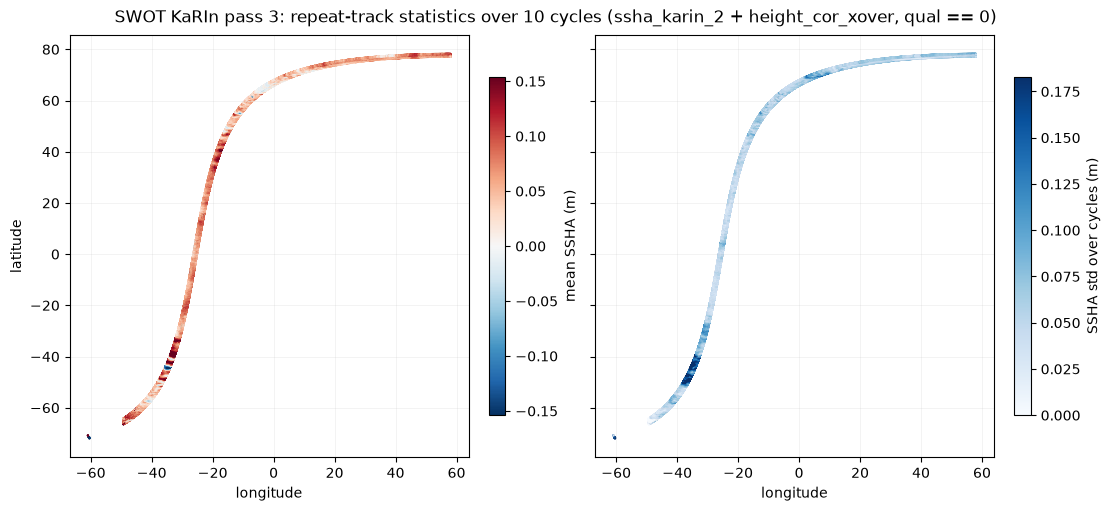

In [17]:
lon = ((sub.longitude + 180) % 360 - 180).values.ravel()
lat = sub.latitude.values.ravel()
lim = float(np.nanpercentile(np.abs(ssha_mean), 98))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True, layout="constrained")
panels = [
    (ssha_mean, "RdBu_r", dict(vmin=-lim, vmax=lim), "mean SSHA (m)"),   # diverging: polarity around 0
    (ssha_std, "Blues", dict(vmin=0, vmax=float(np.nanpercentile(ssha_std, 98))), "SSHA std over cycles (m)"),
]
for ax, (field, cmap, norm, label) in zip(axes, panels):
    sc = ax.scatter(lon, lat, c=field.values.ravel(), s=0.3, cmap=cmap, rasterized=True, **norm)
    fig.colorbar(sc, ax=ax, label=label, shrink=0.8)
    ax.set_xlabel("longitude")
    ax.grid(alpha=0.2, linewidth=0.5)
axes[0].set_ylabel("latitude")
fig.suptitle(f"SWOT KaRIn pass {p}: repeat-track statistics over {n_cycles} cycles "
             f"(ssha_karin_2 + height_cor_xover, qual == 0)")
plt.show()

### Time windows, regions and the flat view
- **Time:** granule times are `(cycle, pass_number)` coordinates, so select with a mask.
- **Region:** the swath grid is fixed per pass, so find the lines inside a box once, then read only those passes.
  (Reads still fetch whole chunks: one chunk per variable per granule.)
- **Flat view:** `stack` gives back the granule-ordered layout of the existing notebook, with holes dropped.

In [18]:
# time window: which slots start in a given week?
t = cube.time_coverage_start.load()
t0 = pd.Series(t.values.ravel()).min()        # pandas skips NaT (empty slots)
start, end = t0 + pd.Timedelta(days=10), t0 + pd.Timedelta(days=31)
ci, pi = np.nonzero(((t >= start) & (t < end)).values)
print(f"slots starting {start:%Y-%m-%d} to {end:%Y-%m-%d}:",
      list(zip(cube.cycle.values[ci].tolist(), cube.pass_number.values[pi].tolist())))

# region: lines of each pass whose swath touches a lat/lon box
box = dict(lat=(-40, -30), lon=(-180, 180))
lat = cube.latitude.sel(pass_number=PASSES)
lat_ok = ((lat >= box["lat"][0]) & (lat <= box["lat"][1])).any("num_pixels")
lines_per_pass = lat_ok.sum("num_lines").to_pandas()
print("lines in latitude band per pass:", lines_per_pass.to_dict())

# flat granule-ordered view, equivalent to the `granule` concat layout
flat = cube.stack(granule=("cycle", "pass_number"))
flat = flat.isel(granule=np.flatnonzero(flat.granule_present.values))
flat = flat.sortby("time_coverage_start")
print(flat.sizes)

slots starting 2024-02-04 to 2024-02-25: [(11, 1), (11, 2), (11, 3), (11, 4), (11, 6), (11, 7), (11, 8)]


lines in latitude band per pass: {1: 582, 2: 582, 3: 582, 4: 582, 5: 582, 6: 582, 7: 582, 8: 582}


Frozen({'num_lines': 9866, 'num_pixels': 69, 'granule': 79, 'num_sides': 2})


## 9. Incremental updates
New granules are published daily, about 28 passes per day. `pass_number` already spans all 584 passes, so only
`cycle` ever grows:

1. If a granule belongs to a cycle the cube doesn't have yet, **append an empty cycle slab** with
   `append_dim="cycle"` (also appending any skipped cycles, so the axis stays contiguous).
2. **Region-write** each run of consecutive passes into its slots, located by label (`region="auto"`). A day is
   one run, or two if it crosses a cycle boundary. Runs are combined but **not padded**, so slots between runs
   (and their granule coordinates) are never touched.
3. A slot that already holds a granule is replaced only if the new one ranks higher (e.g. PGD reprocessing over
   PID). Everything happens in **one commit**, so readers never see a partial update.

The existing slots are read from the small native coordinate arrays with `zarr`. Opening with xarray would decode
`time`, which reads a virtual chunk and would need credentials.

In [19]:
def update(path, new_granules, message=None):
    repo = icechunk.Repository.open(icechunk.local_filesystem_storage(str(path)))
    session = repo.writable_session("main")
    root = zarr.open_group(session.store, mode="r")
    cycles = [int(c) for c in root["cycle"][:]]
    current = {(int(c), int(p)): str(f)
               for c, row in zip(cycles, root["filename"][:])
               for p, f in zip(root["pass_number"][:], row) if f}

    todo = [g for g in new_granules
            if (old := current.get((g.cycle, g.pass_number))) is None or g.rank > rank_filename(old)]
    if not todo:
        print("nothing new")
        return None
    if min(g.cycle for g in todo) < cycles[0]:
        raise ValueError("granules precede the cube's first cycle")

    vdss_new = parse_granules(todo)
    check_consistent(vdss_new, todo)
    new = {(g.cycle, g.pass_number): lift(g, v) for g, v in zip(todo, vdss_new)}

    # 1. grow the cycle axis with empty slabs
    new_cycles = list(range(cycles[-1] + 1, max(g.cycle for g in todo) + 1))
    for c in new_cycles:
        write(empty_cube(next(iter(new.values())), [c], all_passes), session.store, append_dim="cycle")

    # 2. region-write runs of consecutive passes, located by label
    write_runs(session.store, new)
    return session.commit(message or f"update: {len(todo)} granules, new cycles {new_cycles}")

Simulate a daily update: fill the slot dropped in Section 1, add the first passes of the next cycle, and re-offer
granules that are already present (they're skipped). Running the same update again is a no-op.

In [20]:
%%time
next_cycle = CYCLES[-1] + 1
offered = find_granules(sorted({c for c, _ in DROP}), PASSES) + find_granules([next_cycle], PASSES[:4])
print("commit:", update(REPO_PATH, offered))
print("re-run :", update(REPO_PATH, offered))

cube = open_cube(REPO_PATH)
print("cycles:", cube.cycle.values.tolist())
cube.granule_present.sel(pass_number=PASSES).to_pandas().astype(int)

  2026-11-23T23:44:56.342188Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



  cycle 11 passes 5-5: wrote 1
  cycle 20 passes 1-4: wrote 4
commit: AZNYGNCRMFWSTNAFPHS0
nothing new
re-run : None


  2026-11-23T23:45:15.280568Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343

  2026-11-23T23:45:15.301590Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



cycles: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
CPU times: user 2.06 s, sys: 1.49 s, total: 3.55 s
Wall time: 27.9 s


pass_number,1,2,3,4,5,6,7,8
cycle,,,,,,,,
10,1,1,1,1,1,1,1,1
11,1,1,1,1,1,1,1,1
12,1,1,1,1,1,1,1,1
13,1,1,1,1,1,1,1,1
14,1,1,1,1,1,1,1,1
15,1,1,1,1,1,1,1,1
16,1,1,1,1,1,1,1,1
17,1,1,1,1,1,1,1,1
18,1,1,1,1,1,1,1,1


In [21]:
# the newly written slots match their source files
for c, p in sorted(DROP) + [(next_cycle, PASSES[1])]:
    fname = str(cube.filename.sel(cycle=c, pass_number=p).values)
    url = HTTPS_PREFIX + "SWOT_L2_LR_SSH_D/" + fname
    names = ["ssha_karin_2", "time", "latitude_nadir", "ssha_karin_2_qual"]
    direct = read_direct(url, names)
    ok = all(np.array_equal(cube[n].sel(cycle=c, pass_number=p).values, direct[n].values,
                            equal_nan=direct[n].dtype.kind in "fmM") for n in names)
    print(f"cycle {c} pass {p}: matches source = {ok}")

cycle 11 pass 5: matches source = True


cycle 20 pass 2: matches source = True


## 10. Notes and limitations
- **S3 / in-region:** references are relative, so the same store reads over S3 with `open_cube(path, access="s3")`.
  This has been checked as far as is possible outside us-west-2: `earthaccess-auth` obtains S3 credentials and the
  request reaches the correct object, which PO.DAAC then refuses with `AccessDenied` because it comes from outside
  the region. **An in-region S3 read has not been run.** To *build* in-region, parse over S3 with
  `EarthdataS3CredentialProvider` (`to_relative` accepts S3 paths too), and consider the default block reader
  there (see Section 3):
  ```python
  from earthaccess_auth.adapters.obstore import EarthdataS3CredentialProvider
  from obstore.store import S3Store

  s3 = S3Store(S3_BUCKET, region="us-west-2",
               credential_provider=EarthdataS3CredentialProvider.for_bucket(S3_BUCKET))
  registry = ObjectStoreRegistry({f"s3://{S3_BUCKET}": s3})
  ```
- **Retracted granules:** region writes skip empty references, so `update` can replace a granule but not remove
  one. Withdrawn files need their chunk references deleted explicitly.
- **One writer at a time:** `local_filesystem_storage` is not safe for concurrent commits. A production cube
  should use object storage and a single scheduled writer.
- **Growth over time:** each update adds a snapshot. For the full record, look at Icechunk manifest splitting along
  `cycle` and periodic snapshot expiry (not tested here).
- **Dropped variable:** `polarization_karin` (fixed-length character array) is not virtualized.
- **Grid check during builds:** Section 2 samples a few granules. A production build should fail if any granule's
  swath lat/lon differs from the stored grid for its pass.
- **Science phase only:** Cal/Val granules (before 2023-07-26) use a different orbit and `num_lines` (9865).